# Hyperparameter sweep — $\gamma \times K$ (3-month train / 1-month test)

Sweep the two knobs of the production pipeline (`stonks portfolio`) over the **last 4
months** of top-500 daily returns: the **last 3 months fit**, the **last month is held out**.

For each $(\gamma, K)$:
1. factor-model $(\hat\mu, \Sigma_K)$ from the training window (rank-$K$ SVD + diagonal idio);
2. `N_RESTARTS=20` seeded restarts of the softmax gradient ascent (`lr=0.005`, 8000 iters —
   the CLI defaults); the **best restart by training objective** wins, exactly as
   `stonks.portfolio._optimize_long_only` does in production;
3. the frozen weights (after the `min_weight` cleanup + renormalization) are evaluated on the
   held-out month: compounded profit, annualized vol, annualized Sharpe.

Anchors from the current CLI call: $\gamma = 40$, $K = 25$. Benchmarked against 1/N.

Runtime warning: each config costs ~30–60 s (20 restarts × 8000 iters); the default 6×5 grid
takes ~25–30 min. Shrink `GAMMAS`/`KS` for a quicker pass.

*Not financial advice; single-window validation (see the honest-caveats cell at the end).*

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from stonks import get_prices, to_returns
from stonks.portfolio import _factor_covariance, _optimize_long_only

%matplotlib inline

## Parameters

In [2]:
TOP_N = 500
TRAIN_MONTHS = 3
TEST_MONTHS = 1
PERIOD = "2y"       # cached source; we slice the last TRAIN+TEST months

GAMMAS = [5, 10, 20, 40, 80, 160]   # risk aversion (anchor: 40)
KS = [3, 5, 10, 25, 40]             # SVD factors = denoising + concentration dial (anchor: 25)

N_RESTARTS = 20     # per (gamma, K); best restart kept by TRAIN objective
LR = 0.005          # same as the CLI call
ITERS = 8000        # production default in _optimize_long_only
MIN_WEIGHT = 1e-3   # drop tiny weights, renormalize (matches optimize_portfolio)
SEED = 0            # restart r uses seed+r (deterministic)

## Fetch the 4-month window and split train / test

`dropna` on the whole window keeps only stocks with data across **both** periods, so train and
test use the same universe (same trick as `portfolio_oos_test`).

In [3]:
prices = get_prices(top_n=TOP_N, period=PERIOD, interval="1d", field="close")
last = pd.Timestamp(prices.columns[-1])
start = last - pd.DateOffset(months=TRAIN_MONTHS + TEST_MONTHS)
returns = to_returns(prices.loc[:, prices.columns >= start]).dropna()

test_start = last - pd.DateOffset(months=TEST_MONTHS)
train = returns.loc[:, returns.columns < test_start]
test = returns.loc[:, returns.columns >= test_start]

print(f"window ends {last.date()} | {returns.shape[0]} tickers | "
      f"train {train.shape[1]} days ({train.columns[0].date()}..{train.columns[-1].date()}) | "
      f"test {test.shape[1]} days ({test.columns[0].date()}..{test.columns[-1].date()})")

window ends 2026-10-20 | 499 tickers | train 62 days (2026-06-23..2026-09-18) | test 22 days (2026-09-21..2026-10-20)


## Sweep: fit on train (20 restarts), evaluate frozen weights on the test month

$(\hat\mu, \Sigma_K)$ depend only on $K$, so they are computed **once per $K$** and reused
across all $\gamma$. Restart selection uses the **training objective only** — the test month
never touches the fit.

In [4]:
def perf(w, R):
    """(compounded profit, annualized vol, annualized Sharpe) of frozen weights w on R."""
    rp = w @ R
    profit = np.prod(1 + rp) - 1
    vol = rp.std() * np.sqrt(252)
    sharpe = rp.mean() / rp.std() * np.sqrt(252) if rp.std() > 0 else np.nan
    return profit, vol, sharpe


def clean_weights(w_raw, index):
    """min_weight filter + renormalize, sorted descending (optimize_portfolio's output)."""
    ws = pd.Series(w_raw, index=index)
    ws = ws[ws >= MIN_WEIGHT]
    return (ws / ws.sum()).sort_values(ascending=False)


def full_vector(ws, index):
    """Expand cleaned weights back to the full universe (0 for dropped names),
    so they can be matmul-ed against the N-row returns matrix."""
    return ws.reindex(index, fill_value=0.0).to_numpy()


rows = []
weights_by_cfg = {}
t_start = time.time()

for K in KS:
    mu, Sigma = _factor_covariance(train, K)
    for gamma in GAMMAS:
        w_raw, hists = _optimize_long_only(
            mu, Sigma, gamma, iters=ITERS, lr=LR, seed=SEED, n_restarts=N_RESTARTS
        )
        w = clean_weights(w_raw, train.index)
        w_arr = full_vector(w, train.index)
        tr_profit, tr_vol, tr_sharpe = perf(w_arr, train.to_numpy())
        te_profit, te_vol, te_sharpe = perf(w_arr, test.to_numpy())
        weights_by_cfg[(K, gamma)] = w
        rows.append({
            "K": K, "gamma": gamma,
            "train_obj": max(h[-1] for h in hists),
            "n_holdings": len(w),
            "train_profit": tr_profit, "train_sharpe": tr_sharpe,
            "test_profit": te_profit, "test_vol": te_vol, "test_sharpe": te_sharpe,
        })
        print(f"K={K:<3d} gamma={gamma:<5g} | {len(w):3d} holdings | "
              f"test profit {te_profit:+.2%} sharpe {te_sharpe:6.2f} | "
              f"[{time.time() - t_start:6.0f}s elapsed]", flush=True)

results = pd.DataFrame(rows)

K=3   gamma=5     |  71 holdings | test profit +10.51% sharpe   5.43 | [    47s elapsed]


K=3   gamma=10    | 230 holdings | test profit +6.65% sharpe   5.68 | [    93s elapsed]


K=3   gamma=20    | 285 holdings | test profit +4.70% sharpe   5.26 | [   139s elapsed]


K=3   gamma=40    | 285 holdings | test profit +3.91% sharpe   4.92 | [   185s elapsed]


K=3   gamma=80    | 275 holdings | test profit +3.47% sharpe   4.63 | [   232s elapsed]


...

K=40  gamma=10    |   9 holdings | test profit +14.39% sharpe   6.60 | [  1206s elapsed]


K=40  gamma=20    |  16 holdings | test profit +10.32% sharpe   5.96 | [  1252s elapsed]


K=40  gamma=40    |  20 holdings | test profit +7.81% sharpe   5.61 | [  1298s elapsed]


K=40  gamma=80    |  25 holdings | test profit +6.91% sharpe   5.78 | [  1345s elapsed]


K=40  gamma=160   |  38 holdings | test profit +5.54% sharpe   6.04 | [  1389s elapsed]


## 1/N benchmark

The repo's standing result (`portfolio_oos_test`): equal-weight beats every $\hat\mu$-using
mean-variance book on risk-adjusted return out-of-sample. Any sweep winner should be checked
against it.

In [5]:
w_1n = np.full(train.shape[0], 1.0 / train.shape[0])
bench = perf(w_1n, test.to_numpy())
print(f"1/N on test month: profit {bench[0]:+.2%} | vol {bench[1]:.2%} | sharpe {bench[2]:.2f}")

1/N on test month: profit -0.23% | vol 13.23% | sharpe -0.13


## Results, ranked by test Sharpe

The winner is the $(\gamma^*, K^*)$ with the best held-out Sharpe; `train_sharpe` next to it
exposes the in/out-sample gap.

In [6]:
ranked = results.sort_values("test_sharpe", ascending=False).reset_index(drop=True)
ranked.style.format({
    "gamma": "{:g}", "train_obj": "{:.5f}",
    "train_profit": "{:+.2%}", "train_sharpe": "{:.2f}",
    "test_profit": "{:+.2%}", "test_vol": "{:.2%}", "test_sharpe": "{:.2f}",
}).background_gradient(subset=["test_sharpe"], cmap="viridis")

best = ranked.iloc[0]
print(f"winner: K={int(best.K)} gamma={best.gamma:g} "
      f"(test sharpe {best.test_sharpe:.2f} vs 1/N {bench[2]:.2f})")
print(f"production rerun: stonks portfolio --top-n {TOP_N} --months {TRAIN_MONTHS} "
      f"--gamma {best.gamma:g} -k {int(best.K)} --n-restarts {N_RESTARTS} --lr {LR}")

winner: K=25 gamma=160 (test sharpe 8.06 vs 1/N -0.13)
production rerun: stonks portfolio --top-n 500 --months 3 --gamma 160 -k 25 --n-restarts 20 --lr 0.005


## Heatmaps over the $(\gamma, K)$ grid

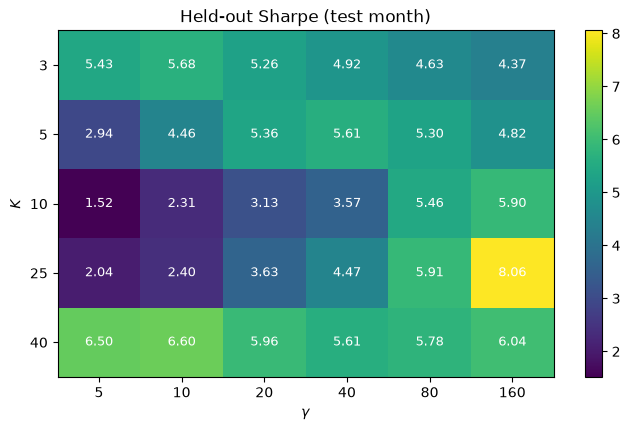

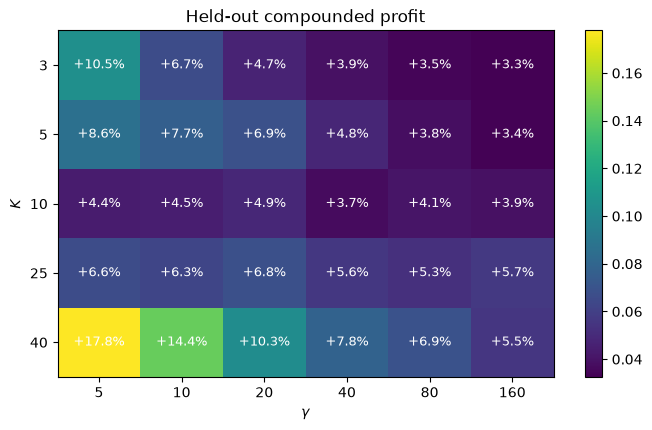

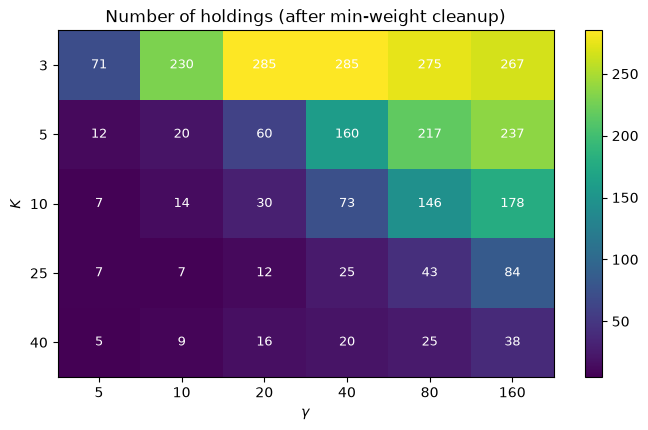

In [7]:
def heatmap(metric, title, fmt="{:.2f}"):
    pivot = results.pivot(index="K", columns="gamma", values=metric)[GAMMAS]
    pivot = pivot.loc[[k for k in KS if k in pivot.index]]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    im = ax.imshow(pivot.to_numpy(), cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(pivot.columns)), [f"{c:g}" for c in pivot.columns])
    ax.set_yticks(range(len(pivot.index)), [f"{i:g}" for i in pivot.index])
    ax.set_xlabel(r"$\gamma$")
    ax.set_ylabel("$K$")
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            ax.text(j, i, fmt.format(pivot.to_numpy()[i, j]),
                    ha="center", va="center", color="white", fontsize=9)
    ax.set_title(title)
    fig.colorbar(im, ax=ax)
    return fig

heatmap("test_sharpe", "Held-out Sharpe (test month)")
heatmap("test_profit", "Held-out compounded profit", fmt="{:+.1%}")
heatmap("n_holdings", "Number of holdings (after min-weight cleanup)", fmt="{:d}")
plt.show()

## The winner on the held-out month

Cumulative return of the winning book vs the anchor config ($K=25, \gamma=40$) and 1/N,
then the winner's top positions.

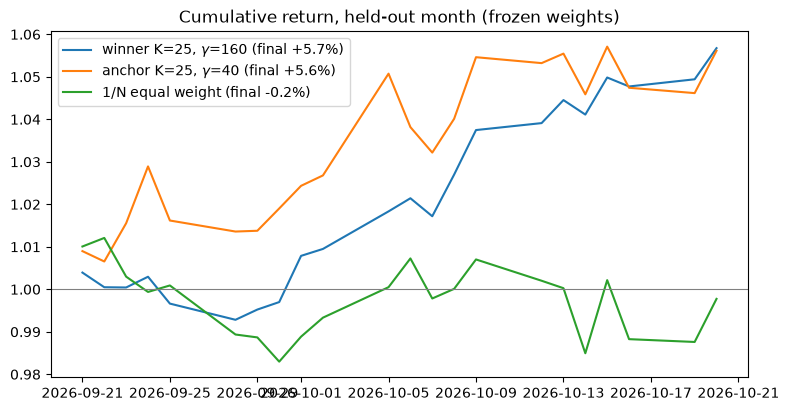

winner holds 84 names; top 15:


,weight
ticker,
TMO,0.054510
CVX,0.040707
UTHR,0.039951
ADP,0.034222
XOM,0.028649
CME,0.028067
BP,0.026297
LNG,0.025104
MRVL,0.024610


In [8]:
anchor_key = (25, 40)
if anchor_key not in weights_by_cfg:
    anchor_key = (min(KS, key=lambda k: abs(k - 25)), min(GAMMAS, key=lambda g: abs(g - 40)))

fig, ax = plt.subplots(figsize=(9, 4.5))
for label, w in [
    (f"winner K={int(best.K)}, $\\gamma$={best.gamma:g}", weights_by_cfg[(int(best.K), best.gamma)]),
    (f"anchor K={anchor_key[0]}, $\\gamma$={anchor_key[1]:g}", weights_by_cfg[anchor_key]),
    ("1/N equal weight", pd.Series(w_1n, index=train.index)),
]:
    eq = (1 + full_vector(w, train.index) @ test.to_numpy()).cumprod()
    ax.plot(test.columns, eq, label=f"{label} (final {eq[-1] - 1:+.1%})")
ax.axhline(1.0, color="gray", lw=0.8)
ax.set_title("Cumulative return, held-out month (frozen weights)")
ax.legend()
plt.show()

print(f"winner holds {int(best.n_holdings)} names; top 15:")
weights_by_cfg[(int(best.K), best.gamma)].head(15).to_frame("weight")

## Honest caveats

- **One test month.** A single 22-day window is noise; adjacent months can rank $(\gamma, K)$
  differently. Walk-forward over several windows is the principled next step (see AGENTS.md).
- **Selection on the test set** makes the winner's numbers optimistic — this sweep is model
  *validation*, not an out-of-sample guarantee.
- **$\hat\mu$ is the weak link.** `portfolio_oos_test` found 1/N beats every $\hat\mu$-using
  mean-variance book OOS on Sharpe; check the winner against the 1/N row above before
  believing it.
- The notebook's winner is fitted on the *train* window (ending a month ago); the production
  rerun command above refits on the **latest** 3 months via the CLI.